## Import

In [1]:
import json, os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Setup

In [2]:
assert os.path.exists("weights_V3_1/regression_lightgbm_kfold_metrics.json"), "oracle must run first"
SEED = 42
np.random.seed(SEED)
boost_rng = np.random.RandomState(SEED)
os.makedirs("weights_V3_1", exist_ok=True)

In [3]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
df = df.dropna(subset=["Income"]).copy()
print("cleaned:", df.shape, "| Income median:", round(df["Income"].median()))

REG_FEATURES = [
    "NumCatalogPurchases", "MntMeatProducts", "MntWines", "NumWebVisitsMonth",
    "MntSweetProducts", "MntFruits", "NumWebPurchases", "MntGoldProds",
    "NumStorePurchases", "MntFishProducts", "Kidhome", "Age", "NumDealsPurchases",
]
X_full = df[REG_FEATURES].values
y_full = df["Income"].astype(float).values
print(f"features: {len(REG_FEATURES)} dims (all numeric)")

cleaned: (2212, 28) | Income median: 51371
features: 13 dims (all numeric)


## Model

In [4]:
def best_split(X, g, h, feat_idx, reg_lambda, min_leaf):
    G_tot, H_tot = g.sum(), h.sum()
    parent = 0.5 * (G_tot ** 2 / (H_tot + reg_lambda))
    best_gain, best_feat, best_thresh = 0.0, None, None
    for f in feat_idx:
        order = np.argsort(X[:, f], kind="mergesort")
        xs, gs, hs = X[order, f], g[order], h[order]
        n = len(xs)
        if n < 2 * min_leaf:
            continue
        cG, cH = np.cumsum(gs), np.cumsum(hs)
        GL, HL = cG[:-1], cH[:-1]
        GR, HR = G_tot - GL, H_tot - HL
        left_n = np.arange(1, n); right_n = n - left_n
        valid = (xs[:-1] != xs[1:]) & (left_n >= min_leaf) & (right_n >= min_leaf)
        if not valid.any():
            continue
        gain = 0.5 * (GL ** 2 / (HL + reg_lambda) + GR ** 2 / (HR + reg_lambda)) - parent
        gain = np.where(valid, gain, -np.inf)
        idx = np.argmax(gain)
        if gain[idx] > best_gain:
            best_gain, best_feat = gain[idx], f
            best_thresh = (xs[idx] + xs[idx + 1]) / 2.0
    return best_feat, best_thresh, best_gain

In [5]:
def build_tree(X, g, h, feat_idx, reg_lambda, min_leaf, max_depth, depth=0):
    G, H = g.sum(), h.sum()
    leaf_val = -G / (H + reg_lambda)
    if depth >= max_depth or len(g) < 2 * min_leaf:
        return {"leaf": True, "value": float(leaf_val)}
    f, thresh, gain = best_split(X, g, h, feat_idx, reg_lambda, min_leaf)
    if f is None or gain <= 1e-12:
        return {"leaf": True, "value": float(leaf_val)}
    mask = X[:, f] <= thresh
    left = build_tree(X[mask], g[mask], h[mask], feat_idx, reg_lambda, min_leaf, max_depth, depth + 1)
    right = build_tree(X[~mask], g[~mask], h[~mask], feat_idx, reg_lambda, min_leaf, max_depth, depth + 1)
    return {"leaf": False, "feature": int(f), "threshold": float(thresh), "left": left, "right": right}

In [6]:
def tree_predict(node, X):
    if X.shape[0] == 0:
        return np.empty(0)
    if node["leaf"]:
        return np.full(X.shape[0], node["value"])
    out = np.empty(X.shape[0])
    mask = X[:, node["feature"]] <= node["threshold"]
    out[mask] = tree_predict(node["left"], X[mask])
    out[~mask] = tree_predict(node["right"], X[~mask])
    return out

In [7]:
MAX_DEPTH, MIN_SAMPLES_LEAF, REG_LAMBDA = 5, 20, 1.0
LEARNING_RATE, N_ROUNDS, PATIENCE = 0.05, 500, 50
ROW_SUBSAMPLE, COL_SUBSAMPLE = 0.8, 0.8
print(f"max_depth={MAX_DEPTH} min_samples_leaf={MIN_SAMPLES_LEAF} reg_lambda={REG_LAMBDA} "
      f"lr={LEARNING_RATE} n_rounds={N_ROUNDS} patience={PATIENCE} row_sub={ROW_SUBSAMPLE} col_sub={COL_SUBSAMPLE}")

max_depth=5 min_samples_leaf=20 reg_lambda=1.0 lr=0.05 n_rounds=500 patience=50 row_sub=0.8 col_sub=0.8


## Sanity Check

In [8]:
from sklearn.tree import DecisionTreeRegressor
rng_chk = np.random.RandomState(0)
X_chk = rng_chk.randn(60, 3)
y_chk = 2 * X_chk[:, 0] - X_chk[:, 1] + 0.1 * rng_chk.randn(60)
g_chk, h_chk = -y_chk, np.ones(60)
my_tree = build_tree(X_chk, g_chk, h_chk, list(range(3)), reg_lambda=0.0, min_leaf=1, max_depth=2)
my_pred = tree_predict(my_tree, X_chk)
sk_tree = DecisionTreeRegressor(max_depth=2, min_samples_leaf=1).fit(X_chk, y_chk)
sk_pred = sk_tree.predict(X_chk)
diff_a = float(np.max(np.abs(my_pred - sk_pred)))
print(f"sanity A: max|our_tree - sklearn_tree| = {diff_a:.3e}")
assert diff_a < 1e-9, "sanity check A FAILED"

sanity A: max|our_tree - sklearn_tree| = 4.441e-16


In [9]:
y_toy = np.array([1.0, 2.0, 3.0]); X_toy = np.zeros((3, 1))
F_toy = np.full(3, 0.0); lr_toy = 0.1
expected_F_after_round = [0.2, 0.38]
toy_losses = []
for r in range(20):
    g_toy, h_toy = F_toy - y_toy, np.ones(3)
    stump = build_tree(X_toy, g_toy, h_toy, [0], reg_lambda=0.0, min_leaf=1, max_depth=0)
    F_toy = F_toy + lr_toy * tree_predict(stump, X_toy)
    if r < 2:
        assert abs(F_toy[0] - expected_F_after_round[r]) < 1e-9, "sanity check B FAILED"
    toy_losses.append(float(np.mean((F_toy - y_toy) ** 2)))
assert all(toy_losses[i] >= toy_losses[i + 1] - 1e-12 for i in range(len(toy_losses) - 1)), "sanity check B FAILED (monotonic)"
print(f"sanity B: closed-form F match | 20-round toy loss monotonic: {toy_losses[0]:.4f} -> {toy_losses[-1]:.4f}")
print("ALL SANITY CHECKS PASSED")

sanity B: closed-form F match | 20-round toy loss monotonic: 3.9067 -> 0.7258
ALL SANITY CHECKS PASSED


## Training

In [10]:
K = 5
kf = KFold(n_splits=K, shuffle=True, random_state=SEED)
fold_rows = []
for fold, (tr_idx, va_idx) in enumerate(kf.split(X_full), start=1):
    Xtr_f, Xva_f = X_full[tr_idx], X_full[va_idx]
    ytr_f, yva_f = y_full[tr_idx], y_full[va_idx]

    X_tr, X_val, y_tr, y_val = train_test_split(Xtr_f, ytr_f, test_size=0.10, random_state=SEED)

    n_tr, n_feat = X_tr.shape
    n_sub_rows = max(MIN_SAMPLES_LEAF * 2, int(round(ROW_SUBSAMPLE * n_tr)))
    n_sub_cols = max(1, int(round(COL_SUBSAMPLE * n_feat)))

    F0 = float(y_tr.mean())
    F_tr, F_val = np.full(n_tr, F0), np.full(len(y_val), F0)

    trees = []
    best_val, best_round, wait = np.inf, 0, 0
    for r in range(1, N_ROUNDS + 1):
        g_full = F_tr - y_tr
        h_full = np.ones(n_tr)

        row_idx = boost_rng.choice(n_tr, size=n_sub_rows, replace=False)
        col_idx = boost_rng.choice(n_feat, size=n_sub_cols, replace=False)
        tree = build_tree(X_tr[row_idx], g_full[row_idx], h_full[row_idx], col_idx,
                           REG_LAMBDA, MIN_SAMPLES_LEAF, MAX_DEPTH)
        trees.append(tree)

        F_tr = F_tr + LEARNING_RATE * tree_predict(tree, X_tr)
        F_val = F_val + LEARNING_RATE * tree_predict(tree, X_val)

        val_rmse = float(np.sqrt(np.mean((F_val - y_val) ** 2)))
        if val_rmse < best_val - 1e-9:
            best_val, best_round, wait = val_rmse, r, 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break

    trees = trees[:best_round]

    F_va = np.full(Xva_f.shape[0], F0)
    for t in trees:
        F_va = F_va + LEARNING_RATE * tree_predict(t, Xva_f)
    mse_v = float(mean_squared_error(yva_f, F_va))
    fold_rows.append({
        "fold": fold,
        "best_iteration": int(best_round),
        "test_loss_MSE_raw": round(mse_v, 1),
        "rmse": round(float(np.sqrt(mse_v)), 1),
        "mae": round(float(mean_absolute_error(yva_f, F_va)), 1),
        "r2": round(float(r2_score(yva_f, F_va)), 4),
    })
    print(f"fold {fold}: RMSE={fold_rows[-1]['rmse']:.1f} R2={fold_rows[-1]['r2']:.4f} best_iter={best_round}")

fold 1: RMSE=8338.9 R2=0.8536 best_iter=497


fold 2: RMSE=10099.8 R2=0.7717 best_iter=500


fold 3: RMSE=7623.6 R2=0.8704 best_iter=485


fold 4: RMSE=10140.1 R2=0.7913 best_iter=499


fold 5: RMSE=8734.7 R2=0.8301 best_iter=370


## K-Fold Summary

In [11]:
kfold_df = pd.DataFrame(fold_rows)
summary = {k: {"mean": round(float(kfold_df[k].mean()), 4), "std": round(float(kfold_df[k].std()), 4)}
           for k in ("test_loss_MSE_raw", "rmse", "mae", "r2")}
print(kfold_df.to_string(index=False))
print(json.dumps(summary, indent=2))
with open("weights_V3_1/regression_scratch_kfold_metrics.json", "w") as f:
    json.dump({"k": K, "folds": fold_rows, "summary": summary}, f, indent=2)

 fold  best_iteration  test_loss_MSE_raw    rmse    mae     r2
    1             497         69537566.1  8338.9 5531.0 0.8536
    2             500        102005300.7 10099.8 5673.6 0.7717
    3             485         58119401.3  7623.6 5495.6 0.8704
    4             499        102822411.3 10140.1 6146.8 0.7913
    5             370         76295820.0  8734.7 5877.2 0.8301
{
  "test_loss_MSE_raw": {
    "mean": 81756099.88,
    "std": 19947558.4631
  },
  "rmse": {
    "mean": 8987.42,
    "std": 1107.9836
  },
  "mae": {
    "mean": 5744.84,
    "std": 270.1917
  },
  "r2": {
    "mean": 0.8234,
    "std": 0.0414
  }
}


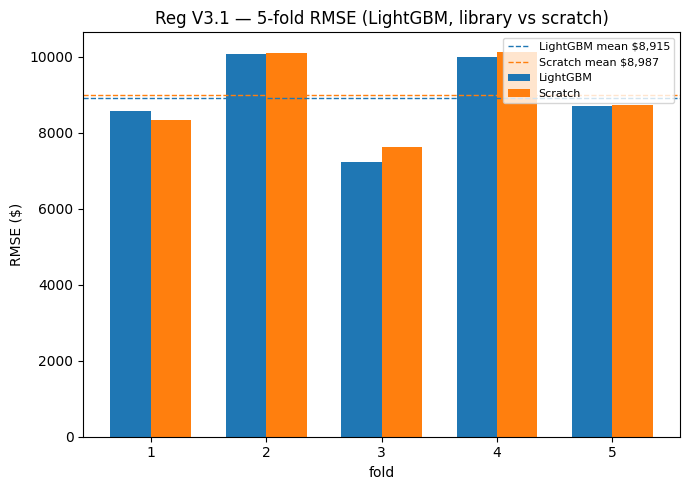

LightGBM RMSE mean+-std: 8914.98 1172.6806
Scratch  RMSE mean+-std: 8987.42 1107.9836


In [12]:
import matplotlib.pyplot as plt

lib_kf = json.load(open("weights_V3_1/regression_lightgbm_kfold_metrics.json"))
scr_kf = json.load(open("weights_V3_1/regression_scratch_kfold_metrics.json"))
lib_rmse = [r["rmse"] for r in lib_kf["folds"]]
scr_rmse = [r["rmse"] for r in scr_kf["folds"]]
folds_x = np.arange(1, 6)
width = 0.35
plt.figure(figsize=(7, 5))
plt.bar(folds_x - width / 2, lib_rmse, width, label="LightGBM")
plt.bar(folds_x + width / 2, scr_rmse, width, label="Scratch")
plt.axhline(lib_kf["summary"]["rmse"]["mean"], color="C0", linestyle="--", linewidth=1,
            label=f"LightGBM mean ${lib_kf['summary']['rmse']['mean']:,.0f}")
plt.axhline(scr_kf["summary"]["rmse"]["mean"], color="C1", linestyle="--", linewidth=1,
            label=f"Scratch mean ${scr_kf['summary']['rmse']['mean']:,.0f}")
plt.xticks(folds_x); plt.xlabel("fold"); plt.ylabel("RMSE ($)")
plt.title("Reg V3.1 — 5-fold RMSE (LightGBM, library vs scratch)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("media/kfold_reg_V3_1.png", dpi=150)
plt.show()

print("LightGBM RMSE mean+-std:", lib_kf["summary"]["rmse"]["mean"], lib_kf["summary"]["rmse"]["std"])
print("Scratch  RMSE mean+-std:", scr_kf["summary"]["rmse"]["mean"], scr_kf["summary"]["rmse"]["std"])